# farquhar2017

Generated by GreenSloth from this model's validations.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mxlpy import scan

In [2]:
import math

import numpy as np
import sympy.physics.units as su
from sympy.physics.units.quantities import Quantity

from mxlpy import Slider, SteadyStateModelBuilder

def _derived_T_K(T_leaf):
    return T_leaf + 273.15

def _derived_Rd(T_leaf, Rd_25, b_Rd, c_Rd):
    return Rd_25 * np.exp((b_Rd * ((T_leaf) - (25))) - (c_Rd * (((T_leaf) ** (2)) - (625))))

def _derived_Gamma_star_Pa(O, c_G, dHa_G, O_ref, R, T_K):
    return np.exp((c_G) - ((dHa_G * 1000) / (R * T_K))) * (O) / (O_ref)

def _derived_Gamma_star(P, Gamma_star_Pa):
    return (Gamma_star_Pa) / (P) * 1000000

def _derived_J(I, f):
    return (I * ((1) - (f))) / (2)

def _derived_I_prime(J):
    return (J) / (4)

def _derived_gt(gt_0, gt_slope, J):
    return gt_0 + gt_slope * J

def _derived_gs(gm_gs, gt):
    return gt * (1 + gm_gs) / (gm_gs)

def _derived_gm(gm_gs, gs):
    return gm_gs * gs

def _derived_gsw(gs):
    return 1.6 * gs

def _derived_A(Ca, Rd, Gamma_star, I_prime, gt):
    return (((I_prime) - (Rd) + gt * (Ca + 2 * Gamma_star)) - (np.pow((((I_prime) - (Rd) + gt * (Ca + 2 * Gamma_star)) ** (2)) - (4 * ((I_prime * gt * ((Ca) - (Gamma_star))) - (Rd * gt * (Ca + 2 * Gamma_star)))), 1 / 2))) / (2)

def _derived_Cc(Ca, gt, A):
    return (Ca) - ((A) / (gt))

def _derived_A_i(Ci, Rd, Gamma_star, I_prime, gm):
    return (((I_prime) - (Rd) + gm * (Ci + 2 * Gamma_star)) - (np.pow((((I_prime) - (Rd) + gm * (Ci + 2 * Gamma_star)) ** (2)) - (4 * ((I_prime * gm * ((Ci) - (Gamma_star))) - (Rd * gm * (Ci + 2 * Gamma_star)))), 1 / 2))) / (2)

def _derived_Cc_i(Ci, gm, A_i):
    return (Ci) - ((A_i) / (gm))

def _derived_Ic(Ca, f, Rd, Gamma_star):
    return (8 * Rd) / ((1) - (f)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca)))

def _derived_m1(Rd, Ic):
    return (Rd) / (Ic)

def _derived_I_half(n_half, Ic):
    return n_half * Ic

def _derived_A_half(Ca, f, Rd, Gamma_star, I_half):
    return ((I_half * ((1) - (f))) / (8) * ((1) - ((Gamma_star) / (0.5 * Ca))) / (1 + 2 * (Gamma_star) / (0.5 * Ca))) - (Rd)

def _derived_m2(n_half, Ic, A_half):
    return (A_half) / (((n_half) - (1)) * Ic)

def _derived_inhibition(Ca, n_half, Gamma_star):
    return (n_half) / ((n_half) - (1)) * ((1) - (((1) - (2 * (Gamma_star) / (Ca))) / (1 + 4 * (Gamma_star) / (Ca)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca))))) * 100

def get_model() -> SteadyStateModelBuilder:
    m = SteadyStateModelBuilder()
    m.add_parameter("I", 100, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="I", tex_name="I", slider=Slider(min="0", max="400", step="1"))
    m.add_parameter("Ca", 400, unit=0.000001, display_name="Ca", tex_name="C_a/P", slider=Slider(min="0", max="2000", step="10"))
    m.add_parameter("Ci", 40.2, unit=0.000001, display_name="Ci", tex_name="C_i/P", slider=Slider(min="0", max="400", step="0.1"))
    m.add_parameter("O", 210, unit=0.001, display_name="O", tex_name="O/P", slider=Slider(min="0", max="400", step="5"))
    m.add_parameter("T_leaf", 25, unit=Quantity("celsius", abbrev="°C"), display_name="T_leaf", tex_name="T", slider=Slider(min="5", max="45", step="0.5"))
    m.add_parameter("P", 100000, unit=su.pascal, display_name="P", tex_name="P")
    m.add_parameter("f", 0.3, unit=None, display_name="f", tex_name="f", slider=Slider(min="0", max="0.9", step="0.01"))
    m.add_parameter("Rd_25", 1, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Rd_25", tex_name="R_{d,25}", slider=Slider(min="0", max="4", step="0.05"))
    m.add_parameter("b_Rd", 0.1012, unit=1/su.kelvin, display_name="b_Rd", tex_name="b_{R_d}")
    m.add_parameter("c_Rd", 0.0005, unit=1/su.kelvin**2, display_name="c_Rd", tex_name="c_{R_d}")
    m.add_parameter("c_G", 20.07, unit=None, display_name="c_G", tex_name="c")
    m.add_parameter("dHa_G", 46.3, unit=su.joule*su.kilo/su.mol, display_name="dHa_G", tex_name="\\Delta H_a")
    m.add_parameter("O_ref", 210, unit=0.001, display_name="O_ref", tex_name="O_{ref}")
    m.add_parameter("R", 8.314, unit=su.joule/(su.kelvin*su.mol), display_name="R", tex_name="R")
    m.add_parameter("gt_0", 0.001, unit=su.mol/(su.meter**2*su.second), display_name="gt_0", tex_name="g_{t,0}", slider=Slider(min="0.0005", max="0.05", step="0.0005"))
    m.add_parameter("gt_slope", 0.0005434782608695652, unit=1000000, display_name="gt_slope", tex_name="s_{g_t}")
    m.add_parameter("gm_gs", 1.5, unit=None, display_name="gm_gs", tex_name="g_m/g_s")
    m.add_parameter("n_half", 6.6, unit=None, display_name="n_half", tex_name="n", slider=Slider(min="1.1", max="20", step="0.1"))
    m.add_derived("T_K", _derived_T_K, args=["T_leaf"], unit=su.kelvin, display_name="T_K", tex_name="T_k")
    m.add_derived("Rd", _derived_Rd, args=["T_leaf", "Rd_25", "b_Rd", "c_Rd"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Rd", tex_name="R_d")
    m.add_derived("Gamma_star_Pa", _derived_Gamma_star_Pa, args=["O", "c_G", "dHa_G", "O_ref", "R", "T_K"], unit=su.pascal, display_name="Gamma_star_Pa", tex_name="\\Gamma^*")
    m.add_derived("Gamma_star", _derived_Gamma_star, args=["P", "Gamma_star_Pa"], unit=0.000001, display_name="Gamma_star", tex_name="\\Gamma^*/P")
    m.add_derived("J", _derived_J, args=["I", "f"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="J", tex_name="J")
    m.add_derived("I_prime", _derived_I_prime, args=["J"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="I_prime", tex_name="I'")
    m.add_derived("gt", _derived_gt, args=["gt_0", "gt_slope", "J"], unit=su.mol/(su.meter**2*su.second), display_name="gt", tex_name="g_t")
    m.add_derived("gs", _derived_gs, args=["gm_gs", "gt"], unit=su.mol/(su.meter**2*su.second), display_name="gs", tex_name="g_s")
    m.add_derived("gm", _derived_gm, args=["gm_gs", "gs"], unit=su.mol/(su.meter**2*su.second), display_name="gm", tex_name="g_m")
    m.add_derived("gsw", _derived_gsw, args=["gs"], unit=su.mol/(su.meter**2*su.second), display_name="gsw", tex_name="g_{sw}")
    m.add_derived("A", _derived_A, args=["Ca", "Rd", "Gamma_star", "I_prime", "gt"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="A", tex_name="A")
    m.add_derived("Cc", _derived_Cc, args=["Ca", "gt", "A"], unit=0.000001, display_name="Cc", tex_name="C_c/P")
    m.add_derived("A_i", _derived_A_i, args=["Ci", "Rd", "Gamma_star", "I_prime", "gm"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="A_i", tex_name="A_{C_i}")
    m.add_derived("Cc_i", _derived_Cc_i, args=["Ci", "gm", "A_i"], unit=0.000001, display_name="Cc_i", tex_name="C_c/P (C_i)")
    m.add_derived("Ic", _derived_Ic, args=["Ca", "f", "Rd", "Gamma_star"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Ic", tex_name="I_c")
    m.add_derived("m1", _derived_m1, args=["Rd", "Ic"], unit=None, display_name="m1", tex_name="m_1")
    m.add_derived("I_half", _derived_I_half, args=["n_half", "Ic"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="I_half", tex_name="I_{0.5}")
    m.add_derived("A_half", _derived_A_half, args=["Ca", "f", "Rd", "Gamma_star", "I_half"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="A_half", tex_name="A_{0.5}")
    m.add_derived("m2", _derived_m2, args=["n_half", "Ic", "A_half"], unit=None, display_name="m2", tex_name="m_2")
    m.add_derived("inhibition", _derived_inhibition, args=["Ca", "n_half", "Gamma_star"], unit=0.01, display_name="inhibition", tex_name="1 - m_2/m_1")
    return m


## Figure 2: conductances, Cc and A against irradiance

In [3]:
data = {"x":[0,100]}
data = {k: np.array(c) for k, c in data.items()}
tables = {}

# Scan i
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201)})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["gt","gsw","gm","Cc","A"]].isna().any(axis=None)
tables["i"] = {
    "x": np.linspace(0, 100, 201),
    "gt": frame["gt"].to_numpy(),
    "gsw": frame["gsw"].to_numpy(),
    "gm": frame["gm"].to_numpy(),
    "Cc": frame["Cc"].to_numpy(),
    "A": frame["A"].to_numpy(),
}

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 2990.82it/s]

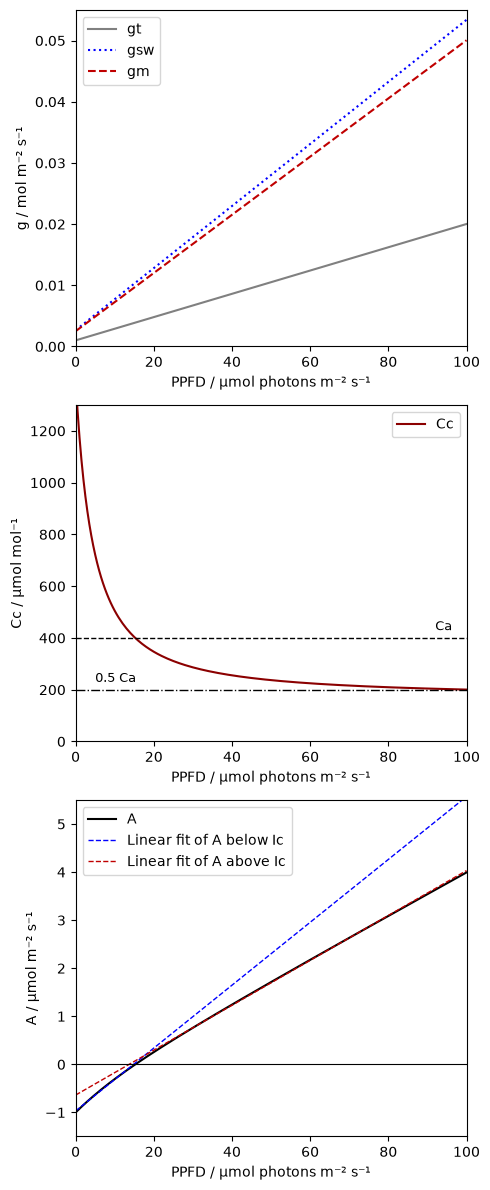

In [4]:
fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(5, 12), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(tables["i"]["x"], tables["i"]["gt"], color="#808080", label="gt")
ax0.plot(tables["i"]["x"], tables["i"]["gsw"], color="blue", ls=":", label="gsw")
ax0.plot(tables["i"]["x"], tables["i"]["gm"], color="#c00000", ls="--", label="gm")
ax0.set_xlabel("PPFD / µmol photons m⁻² s⁻¹")
ax0.set_ylabel("g / mol m⁻² s⁻¹")
ax0.set_xlim(0, 100)
ax0.set_ylim(0, 0.055)
ax0.legend()
ax1 = axs[1, 0]
ax1.text(92, 430, "Ca", fontsize=9)
ax1.text(5, 230, "0.5 Ca", fontsize=9)
ax1.plot(tables["i"]["x"], tables["i"]["Cc"], color="#8b0000", label="Cc")
ax1.set_xlabel("PPFD / µmol photons m⁻² s⁻¹")
ax1.set_ylabel("Cc / µmol mol⁻¹")
ax1.set_xlim(0, 100)
ax1.set_ylim(0, 1300)
ax1.axhline(400, color="black", ls="--", lw=1)
ax1.axhline(200, color="black", ls="-.", lw=1)
ax1.legend()
ax2 = axs[2, 0]
ax2.plot(tables["i"]["x"], tables["i"]["A"], color="black", label="A")
ax2.plot(data["x"], (0.0654 * data["x"]) - (0.9688), color="blue", ls="--", lw=1, label="Linear fit of A below Ic")
ax2.plot(data["x"], (0.0467 * data["x"]) - (0.6383), color="#c00000", ls="--", lw=1, label="Linear fit of A above Ic")
ax2.set_xlabel("PPFD / µmol photons m⁻² s⁻¹")
ax2.set_ylabel("A / µmol m⁻² s⁻¹")
ax2.set_xlim(0, 100)
ax2.set_ylim(-1.5, 5.5)
ax2.axhline(0, color="black", lw=0.8)
ax2.legend()
plt.tight_layout()
plt.show()

## Figure 3(a): A–I at O₂ from 10 to 400 mmol mol⁻¹

In [5]:
tables = {}

# Scan O10
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "O": 10})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["O10"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

# Scan O50
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "O": 50})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["O50"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

# Scan O100
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "O": 100})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["O100"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

# Scan O210
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "O": 210})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["O210"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

# Scan O300
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "O": 300})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["O300"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

# Scan O400
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "O": 400})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["O400"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 2987.36it/s]

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 3125.42it/s]

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 2977.50it/s]

... (2 outputs left out)

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 3079.93it/s]

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 3184.43it/s]

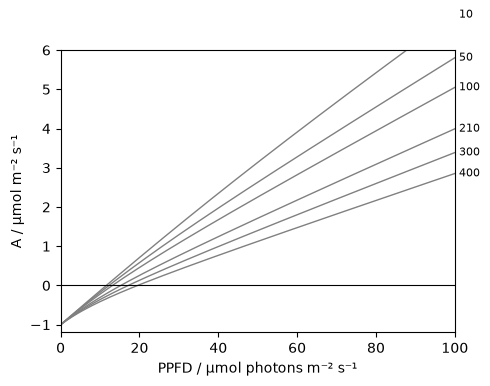

In [6]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(tables["O10"]["x"], tables["O10"]["A"], color="#808080", lw=1)
ax0.annotate("10", (np.asarray(tables["O10"]["x"])[-1], np.asarray(tables["O10"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.plot(tables["O50"]["x"], tables["O50"]["A"], color="#808080", lw=1)
ax0.annotate("50", (np.asarray(tables["O50"]["x"])[-1], np.asarray(tables["O50"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.plot(tables["O100"]["x"], tables["O100"]["A"], color="#808080", lw=1)
ax0.annotate("100", (np.asarray(tables["O100"]["x"])[-1], np.asarray(tables["O100"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.plot(tables["O210"]["x"], tables["O210"]["A"], color="#808080", lw=1)
ax0.annotate("210", (np.asarray(tables["O210"]["x"])[-1], np.asarray(tables["O210"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.plot(tables["O300"]["x"], tables["O300"]["A"], color="#808080", lw=1)
ax0.annotate("300", (np.asarray(tables["O300"]["x"])[-1], np.asarray(tables["O300"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.plot(tables["O400"]["x"], tables["O400"]["A"], color="#808080", lw=1)
ax0.annotate("400", (np.asarray(tables["O400"]["x"])[-1], np.asarray(tables["O400"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.set_xlabel("PPFD / µmol photons m⁻² s⁻¹")
ax0.set_ylabel("A / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 100)
ax0.set_ylim(-1.2, 6)
ax0.axhline(0, color="black", lw=0.8)
plt.tight_layout()
plt.show()

## Figure 4(a): A–I at Ca from 50 to 1600 µmol mol⁻¹

In [7]:
tables = {}

# Scan Ca50
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "Ca": 50})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["Ca50"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

# Scan Ca100
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "Ca": 100})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["Ca100"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

# Scan Ca200
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "Ca": 200})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["Ca200"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

# Scan Ca400
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "Ca": 400})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["Ca400"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

# Scan Ca800
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "Ca": 800})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["Ca800"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

# Scan Ca1600
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "Ca": 1600})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["Ca1600"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 3098.09it/s]

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 3064.14it/s]

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 2966.03it/s]

... (2 outputs left out)

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 3119.32it/s]

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 3097.43it/s]

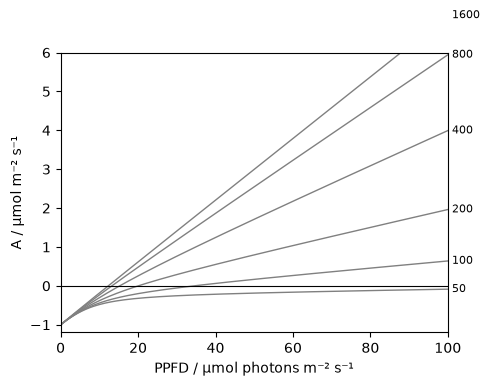

In [8]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(tables["Ca50"]["x"], tables["Ca50"]["A"], color="#808080", lw=1)
ax0.annotate("50", (np.asarray(tables["Ca50"]["x"])[-1], np.asarray(tables["Ca50"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.plot(tables["Ca100"]["x"], tables["Ca100"]["A"], color="#808080", lw=1)
ax0.annotate("100", (np.asarray(tables["Ca100"]["x"])[-1], np.asarray(tables["Ca100"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.plot(tables["Ca200"]["x"], tables["Ca200"]["A"], color="#808080", lw=1)
ax0.annotate("200", (np.asarray(tables["Ca200"]["x"])[-1], np.asarray(tables["Ca200"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.plot(tables["Ca400"]["x"], tables["Ca400"]["A"], color="#808080", lw=1)
ax0.annotate("400", (np.asarray(tables["Ca400"]["x"])[-1], np.asarray(tables["Ca400"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.plot(tables["Ca800"]["x"], tables["Ca800"]["A"], color="#808080", lw=1)
ax0.annotate("800", (np.asarray(tables["Ca800"]["x"])[-1], np.asarray(tables["Ca800"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.plot(tables["Ca1600"]["x"], tables["Ca1600"]["A"], color="#808080", lw=1)
ax0.annotate("1600", (np.asarray(tables["Ca1600"]["x"])[-1], np.asarray(tables["Ca1600"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.set_xlabel("PPFD / µmol photons m⁻² s⁻¹")
ax0.set_ylabel("A / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 100)
ax0.set_ylim(-1.2, 6)
ax0.axhline(0, color="black", lw=0.8)
plt.tight_layout()
plt.show()

## Figure 5: CO₂ efflux into CO₂-free air

In [9]:
tables = {}

# Scan cc_O10
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "Ca": 0, "O": 10})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Cc"]].isna().any(axis=None)
tables["cc_O10"] = {
    "x": np.linspace(0, 100, 201),
    "Cc": frame["Cc"].to_numpy(),
}

# Scan cc_O50
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "Ca": 0, "O": 50})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Cc"]].isna().any(axis=None)
tables["cc_O50"] = {
    "x": np.linspace(0, 100, 201),
    "Cc": frame["Cc"].to_numpy(),
}

# Scan cc_O100
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "Ca": 0, "O": 100})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Cc"]].isna().any(axis=None)
tables["cc_O100"] = {
    "x": np.linspace(0, 100, 201),
    "Cc": frame["Cc"].to_numpy(),
}

# Scan cc_O210
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "Ca": 0, "O": 210})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Cc"]].isna().any(axis=None)
tables["cc_O210"] = {
    "x": np.linspace(0, 100, 201),
    "Cc": frame["Cc"].to_numpy(),
}

# Scan cc_O400
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "Ca": 0, "O": 400})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Cc"]].isna().any(axis=None)
tables["cc_O400"] = {
    "x": np.linspace(0, 100, 201),
    "Cc": frame["Cc"].to_numpy(),
}

# Scan a_O10
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "Ca": 0, "O": 10})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["a_O10"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

# Scan a_O50
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "Ca": 0, "O": 50})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["a_O50"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

# Scan a_O100
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "Ca": 0, "O": 100})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["a_O100"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

# Scan a_O210
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "Ca": 0, "O": 210})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["a_O210"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

# Scan a_O400
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "Ca": 0, "O": 400})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["a_O400"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

  0%|          | 0/201 [00:00<?, ?it/s]

/tmp/ipykernel_103434/2466791121.py:52: RuntimeWarning: divide by zero encountered in scalar divide
  return (8 * Rd) / ((1) - (f)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca)))
/tmp/ipykernel_103434/2466791121.py:52: RuntimeWarning: invalid value encountered in scalar divide
  return (8 * Rd) / ((1) - (f)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca)))
/tmp/ipykernel_103434/2466791121.py:61: RuntimeWarning: divide by zero encountered in scalar divide
  return ((I_half * ((1) - (f))) / (8) * ((1) - ((Gamma_star) / (0.5 * Ca))) / (1 + 2 * (Gamma_star) / (0.5 * Ca))) - (Rd)
/tmp/ipykernel_103434/2466791121.py:67: RuntimeWarning: divide by zero encountered in scalar divide
  return (n_half) / ((n_half) - (1)) * ((1) - (((1) - (2 * (Gamma_star) / (Ca))) / (1 + 4 * (Gamma_star) / (Ca)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca))))) * 100
/tmp/ipykernel_103434/2466791121.py:67: RuntimeWarning: invalid value encountered in scalar divide
  

/tmp/ipykernel_103434/2466791121.py:52: RuntimeWarning: divide by zero encountered in scalar divide
  return (8 * Rd) / ((1) - (f)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca)))
/tmp/ipykernel_103434/2466791121.py:52: RuntimeWarning: invalid value encountered in scalar divide
  return (8 * Rd) / ((1) - (f)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca)))
/tmp/ipykernel_103434/2466791121.py:61: RuntimeWarning: divide by zero encountered in scalar divide
  return ((I_half * ((1) - (f))) / (8) * ((1) - ((Gamma_star) / (0.5 * Ca))) / (1 + 2 * (Gamma_star) / (0.5 * Ca))) - (Rd)
/tmp/ipykernel_103434/2466791121.py:67: RuntimeWarning: divide by zero encountered in scalar divide
  return (n_half) / ((n_half) - (1)) * ((1) - (((1) - (2 * (Gamma_star) / (Ca))) / (1 + 4 * (Gamma_star) / (Ca)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca))))) * 100
/tmp/ipykernel_103434/2466791121.py:67: RuntimeWarning: invalid value encountered in scalar divide
  

  0%|          | 0/201 [00:00<?, ?it/s]

/tmp/ipykernel_103434/2466791121.py:52: RuntimeWarning: divide by zero encountered in scalar divide
  return (8 * Rd) / ((1) - (f)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca)))
/tmp/ipykernel_103434/2466791121.py:52: RuntimeWarning: invalid value encountered in scalar divide
  return (8 * Rd) / ((1) - (f)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca)))
/tmp/ipykernel_103434/2466791121.py:61: RuntimeWarning: divide by zero encountered in scalar divide
  return ((I_half * ((1) - (f))) / (8) * ((1) - ((Gamma_star) / (0.5 * Ca))) / (1 + 2 * (Gamma_star) / (0.5 * Ca))) - (Rd)
/tmp/ipykernel_103434/2466791121.py:67: RuntimeWarning: divide by zero encountered in scalar divide
  return (n_half) / ((n_half) - (1)) * ((1) - (((1) - (2 * (Gamma_star) / (Ca))) / (1 + 4 * (Gamma_star) / (Ca)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca))))) * 100
/tmp/ipykernel_103434/2466791121.py:67: RuntimeWarning: invalid value encountered in scalar divide
  

/tmp/ipykernel_103434/2466791121.py:61: RuntimeWarning: divide by zero encountered in scalar divide
  return ((I_half * ((1) - (f))) / (8) * ((1) - ((Gamma_star) / (0.5 * Ca))) / (1 + 2 * (Gamma_star) / (0.5 * Ca))) - (Rd)
/tmp/ipykernel_103434/2466791121.py:67: RuntimeWarning: divide by zero encountered in scalar divide
  return (n_half) / ((n_half) - (1)) * ((1) - (((1) - (2 * (Gamma_star) / (Ca))) / (1 + 4 * (Gamma_star) / (Ca)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca))))) * 100
/tmp/ipykernel_103434/2466791121.py:67: RuntimeWarning: invalid value encountered in scalar divide
  return (n_half) / ((n_half) - (1)) * ((1) - (((1) - (2 * (Gamma_star) / (Ca))) / (1 + 4 * (Gamma_star) / (Ca)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca))))) * 100
/tmp/ipykernel_103434/2466791121.py:52: RuntimeWarning: divide by zero encountered in scalar divide
  return (8 * Rd) / ((1) - (f)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca)))
/tmp/ipykern

... (27 outputs left out)

  0%|          | 0/201 [00:00<?, ?it/s]

/tmp/ipykernel_103434/2466791121.py:52: RuntimeWarning: divide by zero encountered in scalar divide
  return (8 * Rd) / ((1) - (f)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca)))
/tmp/ipykernel_103434/2466791121.py:52: RuntimeWarning: invalid value encountered in scalar divide
  return (8 * Rd) / ((1) - (f)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca)))
/tmp/ipykernel_103434/2466791121.py:61: RuntimeWarning: divide by zero encountered in scalar divide
  return ((I_half * ((1) - (f))) / (8) * ((1) - ((Gamma_star) / (0.5 * Ca))) / (1 + 2 * (Gamma_star) / (0.5 * Ca))) - (Rd)
/tmp/ipykernel_103434/2466791121.py:67: RuntimeWarning: divide by zero encountered in scalar divide
  return (n_half) / ((n_half) - (1)) * ((1) - (((1) - (2 * (Gamma_star) / (Ca))) / (1 + 4 * (Gamma_star) / (Ca)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca))))) * 100
/tmp/ipykernel_103434/2466791121.py:67: RuntimeWarning: invalid value encountered in scalar divide
  

/tmp/ipykernel_103434/2466791121.py:52: RuntimeWarning: divide by zero encountered in scalar divide
  return (8 * Rd) / ((1) - (f)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca)))
/tmp/ipykernel_103434/2466791121.py:52: RuntimeWarning: invalid value encountered in scalar divide
  return (8 * Rd) / ((1) - (f)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca)))
/tmp/ipykernel_103434/2466791121.py:61: RuntimeWarning: divide by zero encountered in scalar divide
  return ((I_half * ((1) - (f))) / (8) * ((1) - ((Gamma_star) / (0.5 * Ca))) / (1 + 2 * (Gamma_star) / (0.5 * Ca))) - (Rd)
/tmp/ipykernel_103434/2466791121.py:67: RuntimeWarning: divide by zero encountered in scalar divide
  return (n_half) / ((n_half) - (1)) * ((1) - (((1) - (2 * (Gamma_star) / (Ca))) / (1 + 4 * (Gamma_star) / (Ca)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca))))) * 100
/tmp/ipykernel_103434/2466791121.py:67: RuntimeWarning: invalid value encountered in scalar divide
  

/tmp/ipykernel_103434/2466791121.py:52: RuntimeWarning: divide by zero encountered in scalar divide
  return (8 * Rd) / ((1) - (f)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca)))
/tmp/ipykernel_103434/2466791121.py:52: RuntimeWarning: invalid value encountered in scalar divide
  return (8 * Rd) / ((1) - (f)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca)))
/tmp/ipykernel_103434/2466791121.py:61: RuntimeWarning: divide by zero encountered in scalar divide
  return ((I_half * ((1) - (f))) / (8) * ((1) - ((Gamma_star) / (0.5 * Ca))) / (1 + 2 * (Gamma_star) / (0.5 * Ca))) - (Rd)
/tmp/ipykernel_103434/2466791121.py:67: RuntimeWarning: divide by zero encountered in scalar divide
  return (n_half) / ((n_half) - (1)) * ((1) - (((1) - (2 * (Gamma_star) / (Ca))) / (1 + 4 * (Gamma_star) / (Ca)) * (1 + 2 * (Gamma_star) / (Ca)) / ((1) - ((Gamma_star) / (Ca))))) * 100
/tmp/ipykernel_103434/2466791121.py:67: RuntimeWarning: invalid value encountered in scalar divide
  

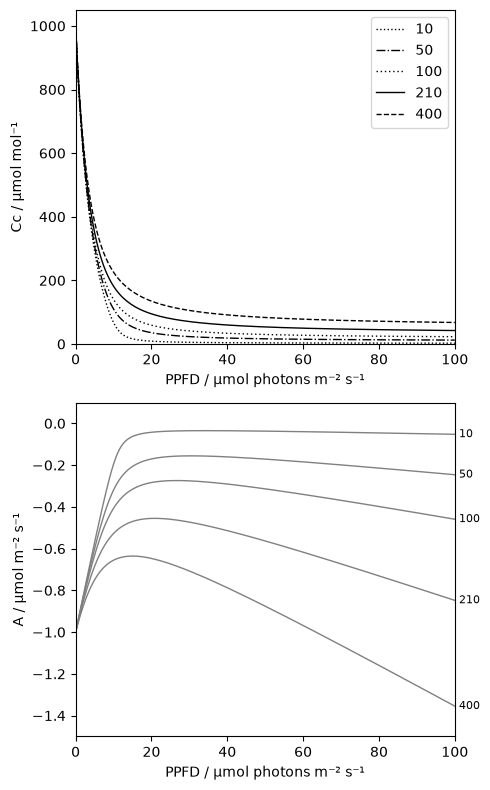

In [10]:
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(5, 8), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(tables["cc_O10"]["x"], tables["cc_O10"]["Cc"], color="black", ls=":", lw=1, label="10")
ax0.plot(tables["cc_O50"]["x"], tables["cc_O50"]["Cc"], color="black", ls="-.", lw=1, label="50")
ax0.plot(tables["cc_O100"]["x"], tables["cc_O100"]["Cc"], color="black", ls=(0, [1,2]), lw=1, label="100")
ax0.plot(tables["cc_O210"]["x"], tables["cc_O210"]["Cc"], color="black", ls="-", lw=1, label="210")
ax0.plot(tables["cc_O400"]["x"], tables["cc_O400"]["Cc"], color="black", ls="--", lw=1, label="400")
ax0.set_xlabel("PPFD / µmol photons m⁻² s⁻¹")
ax0.set_ylabel("Cc / µmol mol⁻¹")
ax0.set_xlim(0, 100)
ax0.set_ylim(0, 1050)
ax0.legend()
ax1 = axs[1, 0]
ax1.plot(tables["a_O10"]["x"], tables["a_O10"]["A"], color="#808080", lw=1)
ax1.annotate("10", (np.asarray(tables["a_O10"]["x"])[-1], np.asarray(tables["a_O10"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax1.plot(tables["a_O50"]["x"], tables["a_O50"]["A"], color="#808080", lw=1)
ax1.annotate("50", (np.asarray(tables["a_O50"]["x"])[-1], np.asarray(tables["a_O50"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax1.plot(tables["a_O100"]["x"], tables["a_O100"]["A"], color="#808080", lw=1)
ax1.annotate("100", (np.asarray(tables["a_O100"]["x"])[-1], np.asarray(tables["a_O100"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax1.plot(tables["a_O210"]["x"], tables["a_O210"]["A"], color="#808080", lw=1)
ax1.annotate("210", (np.asarray(tables["a_O210"]["x"])[-1], np.asarray(tables["a_O210"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax1.plot(tables["a_O400"]["x"], tables["a_O400"]["A"], color="#808080", lw=1)
ax1.annotate("400", (np.asarray(tables["a_O400"]["x"])[-1], np.asarray(tables["a_O400"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax1.set_xlabel("PPFD / µmol photons m⁻² s⁻¹")
ax1.set_ylabel("A / µmol m⁻² s⁻¹")
ax1.set_xlim(0, 100)
ax1.set_ylim(-1.5, 0.1)
plt.tight_layout()
plt.show()

## Figure 6(a): A–I at leaf temperatures from 15 to 40 °C

In [11]:
tables = {}

# Scan T_leaf15
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "T_leaf": 15})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["T_leaf15"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

# Scan T_leaf20
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "T_leaf": 20})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["T_leaf20"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

# Scan T_leaf25
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "T_leaf": 25})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["T_leaf25"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

# Scan T_leaf30
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "T_leaf": 30})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["T_leaf30"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

# Scan T_leaf35
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "T_leaf": 35})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["T_leaf35"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

# Scan T_leaf40
to_scan = pd.DataFrame({"I": np.linspace(0, 100, 201), "T_leaf": 40})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["T_leaf40"] = {
    "x": np.linspace(0, 100, 201),
    "A": frame["A"].to_numpy(),
}

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 3221.86it/s]

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 3557.64it/s]

  0%|          | 0/201 [00:00<?, ?it/s]

 24%|██▍       | 48/201 [00:00<00:00, 479.83it/s]

... (3 outputs left out)

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 3621.25it/s]

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 3614.91it/s]

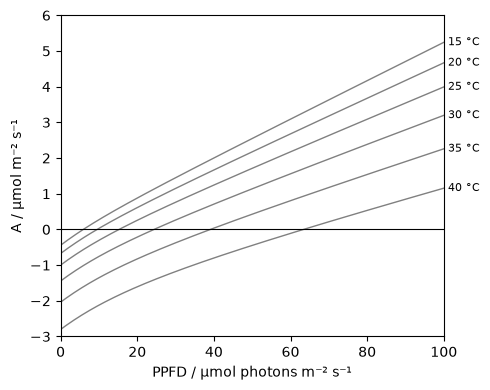

In [12]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(tables["T_leaf15"]["x"], tables["T_leaf15"]["A"], color="#808080", lw=1)
ax0.annotate("15 °C", (np.asarray(tables["T_leaf15"]["x"])[-1], np.asarray(tables["T_leaf15"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.plot(tables["T_leaf20"]["x"], tables["T_leaf20"]["A"], color="#808080", lw=1)
ax0.annotate("20 °C", (np.asarray(tables["T_leaf20"]["x"])[-1], np.asarray(tables["T_leaf20"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.plot(tables["T_leaf25"]["x"], tables["T_leaf25"]["A"], color="#808080", lw=1)
ax0.annotate("25 °C", (np.asarray(tables["T_leaf25"]["x"])[-1], np.asarray(tables["T_leaf25"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.plot(tables["T_leaf30"]["x"], tables["T_leaf30"]["A"], color="#808080", lw=1)
ax0.annotate("30 °C", (np.asarray(tables["T_leaf30"]["x"])[-1], np.asarray(tables["T_leaf30"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.plot(tables["T_leaf35"]["x"], tables["T_leaf35"]["A"], color="#808080", lw=1)
ax0.annotate("35 °C", (np.asarray(tables["T_leaf35"]["x"])[-1], np.asarray(tables["T_leaf35"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.plot(tables["T_leaf40"]["x"], tables["T_leaf40"]["A"], color="#808080", lw=1)
ax0.annotate("40 °C", (np.asarray(tables["T_leaf40"]["x"])[-1], np.asarray(tables["T_leaf40"]["A"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.set_xlabel("PPFD / µmol photons m⁻² s⁻¹")
ax0.set_ylabel("A / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 100)
ax0.set_ylim(-3, 6)
ax0.axhline(0, color="black", lw=0.8)
plt.tight_layout()
plt.show()

## Figure 7: the Laisk approach, A at constant Ci

In [13]:
tables = {}

# Scan ci0
to_scan = pd.DataFrame({"I": np.linspace(0, 400, 401), "Ci": 37})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_i"]].isna().any(axis=None)
tables["ci0"] = {
    "x": np.linspace(0, 400, 401),
    "A_i": frame["A_i"].to_numpy(),
}

# Scan ci1
to_scan = pd.DataFrame({"I": np.linspace(0, 400, 401), "Ci": 40.2})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_i"]].isna().any(axis=None)
tables["ci1"] = {
    "x": np.linspace(0, 400, 401),
    "A_i": frame["A_i"].to_numpy(),
}

# Scan ci2
to_scan = pd.DataFrame({"I": np.linspace(0, 400, 401), "Ci": 43})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_i"]].isna().any(axis=None)
tables["ci2"] = {
    "x": np.linspace(0, 400, 401),
    "A_i": frame["A_i"].to_numpy(),
}

# Scan ci3
to_scan = pd.DataFrame({"I": np.linspace(0, 400, 401), "Ci": 46})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_i"]].isna().any(axis=None)
tables["ci3"] = {
    "x": np.linspace(0, 400, 401),
    "A_i": frame["A_i"].to_numpy(),
}

# Scan pts_ci0
to_scan = pd.DataFrame({"I": np.array([75,125,200,300,400]), "Ci": 37})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_i"]].isna().any(axis=None)
tables["pts_ci0"] = {
    "x": np.array([75,125,200,300,400]),
    "A_i": frame["A_i"].to_numpy(),
}

# Scan pts_ci1
to_scan = pd.DataFrame({"I": np.array([75,125,200,300,400]), "Ci": 40.2})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_i"]].isna().any(axis=None)
tables["pts_ci1"] = {
    "x": np.array([75,125,200,300,400]),
    "A_i": frame["A_i"].to_numpy(),
}

# Scan pts_ci2
to_scan = pd.DataFrame({"I": np.array([75,125,200,300,400]), "Ci": 43})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_i"]].isna().any(axis=None)
tables["pts_ci2"] = {
    "x": np.array([75,125,200,300,400]),
    "A_i": frame["A_i"].to_numpy(),
}

# Scan pts_ci3
to_scan = pd.DataFrame({"I": np.array([75,125,200,300,400]), "Ci": 46})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_i"]].isna().any(axis=None)
tables["pts_ci3"] = {
    "x": np.array([75,125,200,300,400]),
    "A_i": frame["A_i"].to_numpy(),
}

# Scan i75
to_scan = pd.DataFrame({"Ci": np.linspace(36, 48, 121), "I": 75})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_i"]].isna().any(axis=None)
tables["i75"] = {
    "x": np.linspace(36, 48, 121),
    "A_i": frame["A_i"].to_numpy(),
}

# Scan i125
to_scan = pd.DataFrame({"Ci": np.linspace(36, 48, 121), "I": 125})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_i"]].isna().any(axis=None)
tables["i125"] = {
    "x": np.linspace(36, 48, 121),
    "A_i": frame["A_i"].to_numpy(),
}

# Scan i200
to_scan = pd.DataFrame({"Ci": np.linspace(36, 48, 121), "I": 200})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_i"]].isna().any(axis=None)
tables["i200"] = {
    "x": np.linspace(36, 48, 121),
    "A_i": frame["A_i"].to_numpy(),
}

# Scan i300
to_scan = pd.DataFrame({"Ci": np.linspace(36, 48, 121), "I": 300})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_i"]].isna().any(axis=None)
tables["i300"] = {
    "x": np.linspace(36, 48, 121),
    "A_i": frame["A_i"].to_numpy(),
}

# Scan i400
to_scan = pd.DataFrame({"Ci": np.linspace(36, 48, 121), "I": 400})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_i"]].isna().any(axis=None)
tables["i400"] = {
    "x": np.linspace(36, 48, 121),
    "A_i": frame["A_i"].to_numpy(),
}

  0%|          | 0/401 [00:00<?, ?it/s]

 92%|█████████▏| 367/401 [00:00<00:00, 3669.32it/s]

100%|██████████| 401/401 [00:00<00:00, 3651.67it/s]

  0%|          | 0/401 [00:00<?, ?it/s]

 92%|█████████▏| 367/401 [00:00<00:00, 3662.02it/s]

100%|██████████| 401/401 [00:00<00:00, 3641.85it/s]

... (20 outputs left out)

  0%|          | 0/121 [00:00<?, ?it/s]

100%|██████████| 121/121 [00:00<00:00, 3696.69it/s]

  0%|          | 0/121 [00:00<?, ?it/s]

100%|██████████| 121/121 [00:00<00:00, 3365.08it/s]

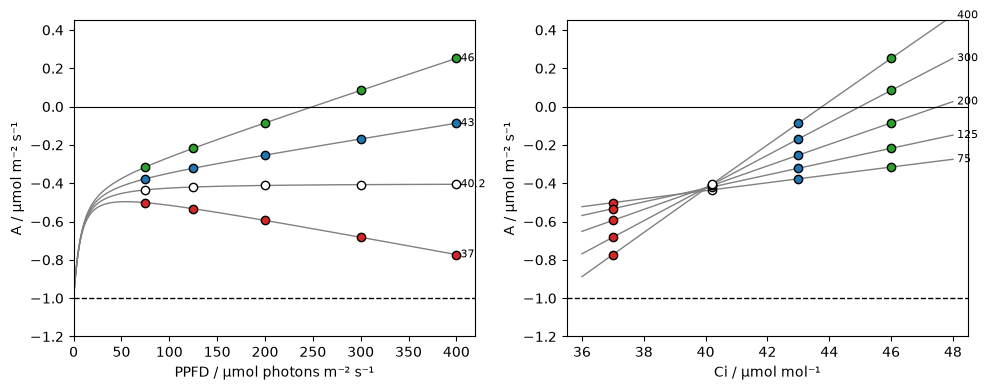

In [14]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(tables["ci0"]["x"], tables["ci0"]["A_i"], color="#808080", lw=1)
ax0.annotate("37", (np.asarray(tables["ci0"]["x"])[-1], np.asarray(tables["ci0"]["A_i"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.plot(tables["ci1"]["x"], tables["ci1"]["A_i"], color="#808080", lw=1)
ax0.annotate("40.2", (np.asarray(tables["ci1"]["x"])[-1], np.asarray(tables["ci1"]["A_i"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.plot(tables["ci2"]["x"], tables["ci2"]["A_i"], color="#808080", lw=1)
ax0.annotate("43", (np.asarray(tables["ci2"]["x"])[-1], np.asarray(tables["ci2"]["A_i"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.plot(tables["ci3"]["x"], tables["ci3"]["A_i"], color="#808080", lw=1)
ax0.annotate("46", (np.asarray(tables["ci3"]["x"])[-1], np.asarray(tables["ci3"]["A_i"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax0.plot(tables["pts_ci0"]["x"], tables["pts_ci0"]["A_i"], color="#d62728", ls="none", marker="o", markerfacecolor="#d62728", markeredgecolor="black")
ax0.plot(tables["pts_ci1"]["x"], tables["pts_ci1"]["A_i"], color="white", ls="none", marker="o", markerfacecolor="white", markeredgecolor="black")
ax0.plot(tables["pts_ci2"]["x"], tables["pts_ci2"]["A_i"], color="#1f77b4", ls="none", marker="o", markerfacecolor="#1f77b4", markeredgecolor="black")
ax0.plot(tables["pts_ci3"]["x"], tables["pts_ci3"]["A_i"], color="#2ca02c", ls="none", marker="o", markerfacecolor="#2ca02c", markeredgecolor="black")
ax0.set_xlabel("PPFD / µmol photons m⁻² s⁻¹")
ax0.set_ylabel("A / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 420)
ax0.set_ylim(-1.2, 0.45)
ax0.axhline(0, color="black", lw=0.8)
ax0.axhline(-1, color="black", ls="--", lw=1)
ax1 = axs[0, 1]
ax1.plot(tables["i75"]["x"], tables["i75"]["A_i"], color="#808080", lw=1)
ax1.annotate("75", (np.asarray(tables["i75"]["x"])[-1], np.asarray(tables["i75"]["A_i"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax1.plot(tables["i125"]["x"], tables["i125"]["A_i"], color="#808080", lw=1)
ax1.annotate("125", (np.asarray(tables["i125"]["x"])[-1], np.asarray(tables["i125"]["A_i"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax1.plot(tables["i200"]["x"], tables["i200"]["A_i"], color="#808080", lw=1)
ax1.annotate("200", (np.asarray(tables["i200"]["x"])[-1], np.asarray(tables["i200"]["A_i"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax1.plot(tables["i300"]["x"], tables["i300"]["A_i"], color="#808080", lw=1)
ax1.annotate("300", (np.asarray(tables["i300"]["x"])[-1], np.asarray(tables["i300"]["A_i"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax1.plot(tables["i400"]["x"], tables["i400"]["A_i"], color="#808080", lw=1)
ax1.annotate("400", (np.asarray(tables["i400"]["x"])[-1], np.asarray(tables["i400"]["A_i"])[-1]), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
ax1.plot(tables["pts_ci0"]["x"] * 0 + 37, tables["pts_ci0"]["A_i"], color="#d62728", ls="none", marker="o", markerfacecolor="#d62728", markeredgecolor="black")
ax1.plot(tables["pts_ci1"]["x"] * 0 + 40.2, tables["pts_ci1"]["A_i"], color="white", ls="none", marker="o", markerfacecolor="white", markeredgecolor="black")
ax1.plot(tables["pts_ci2"]["x"] * 0 + 43, tables["pts_ci2"]["A_i"], color="#1f77b4", ls="none", marker="o", markerfacecolor="#1f77b4", markeredgecolor="black")
ax1.plot(tables["pts_ci3"]["x"] * 0 + 46, tables["pts_ci3"]["A_i"], color="#2ca02c", ls="none", marker="o", markerfacecolor="#2ca02c", markeredgecolor="black")
ax1.set_xlabel("Ci / µmol mol⁻¹")
ax1.set_ylabel("A / µmol m⁻² s⁻¹")
ax1.set_xlim(35.5, 48.5)
ax1.set_ylim(-1.2, 0.45)
ax1.axhline(0, color="black", lw=0.8)
ax1.axhline(-1, color="black", ls="--", lw=1)
plt.tight_layout()
plt.show()